

### Objective
Represent face images numerically, implement PCA using NumPy linear algebra, visualize eigenfaces and reconstruction, perform similarity-based recognition, and compare PCA features with traditional ML classifiers.



## Part A — Image representation



In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import csv
import json
import os
import time

SEED = 42
from pathlib import Path

DATA_DIR = Path(r"C:\Users\diash\OneDrive\Desktop\python\lab 7")

print("Dataset exists:", DATA_DIR.exists())
print("Subject folders:", len([
    p for p in DATA_DIR.glob("s*")
    if p.is_dir()
]))
OUTPUT_DIR = Path("outputs")
FIGURE_DIR = OUTPUT_DIR / "figures"
RECON_DIR = OUTPUT_DIR / "reconstructions"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
RECON_DIR.mkdir(parents=True, exist_ok=True)


if not DATA_DIR.exists():
    candidates = [Path("ORL"), Path("data"), Path(".")]
    for candidate in candidates:
        if (candidate / "s1").is_dir():
            DATA_DIR = candidate
            break

subject_dirs = sorted(
    [p for p in DATA_DIR.glob("s*") if p.is_dir()],
    key=lambda p: int(p.name[1:])
)
assert len(subject_dirs) == 40, (
    f"Expected 40 subject folders under {DATA_DIR}, found {len(subject_dirs)}. "
    "Check that the ORL archive is extracted correctly."
)

images, labels, image_ids, image_paths = [], [], [], []
for folder in subject_dirs:
    subject_id = int(folder.name[1:])
    for image_id in range(1, 11):
        path = folder / f"{image_id}.pgm"
        if not path.exists():
            raise FileNotFoundError(f"Missing image: {path}")
        image = np.asarray(Image.open(path).convert("L"), dtype=np.float64)
        images.append(image)
        labels.append(subject_id)
        image_ids.append(image_id)
        image_paths.append(str(path))

images = np.stack(images)
labels = np.asarray(labels, dtype=int)
image_ids = np.asarray(image_ids, dtype=int)
X = images.reshape(len(images), -1)

print("Image tensor shape:", images.shape)
print("Flattened image matrix shape:", X.shape)
print("Number of subjects:", len(np.unique(labels)))
print("Images per subject:", len(images) // len(np.unique(labels)))
print("Pixel intensity range:", X.min(), "to", X.max())
print("First image path:", image_paths[0])

Dataset exists: True
Subject folders: 40
Image tensor shape: (400, 112, 92)
Flattened image matrix shape: (400, 10304)
Number of subjects: 40
Images per subject: 10
Pixel intensity range: 0.0 to 251.0
First image path: C:\Users\diash\OneDrive\Desktop\python\lab 7\s1\1.pgm


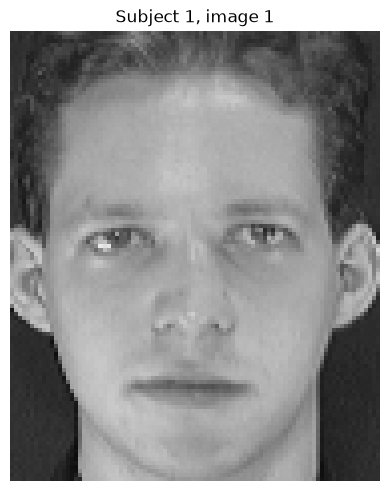

Sample image dimensions: (112, 92)
Top-left 5 × 5 pixel intensities:
[[48 49 45 47 49]
 [45 52 39 46 56]
 [45 50 42 51 51]
 [49 46 47 47 50]
 [46 46 47 48 48]]


In [3]:
# Display one image and inspect its pixel matrix.
sample_index = 0
plt.figure(figsize=(4, 5))
plt.imshow(images[sample_index], cmap="gray", vmin=0, vmax=255)
plt.title(f"Subject {labels[sample_index]}, image {image_ids[sample_index]}")
plt.axis("off")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "sample_face.png", dpi=150, bbox_inches="tight")
plt.show()

print("Sample image dimensions:", images[sample_index].shape)
print("Top-left 5 × 5 pixel intensities:")
print(images[sample_index][:5, :5].astype(int))

In [4]:
# Reproducible subject-wise split: images 1–7 train, 8–10 test.
train_mask = image_ids <= 7
test_mask = image_ids >= 8

X_train_raw, y_train = X[train_mask], labels[train_mask]
X_test_raw, y_test = X[test_mask], labels[test_mask]
train_images = images[train_mask]
test_images = images[test_mask]

print("Training matrix:", X_train_raw.shape)
print("Testing matrix:", X_test_raw.shape)
print("Train subjects:", len(np.unique(y_train)))
print("Test subjects:", len(np.unique(y_test)))
assert set(np.unique(y_train)) == set(np.unique(y_test)) == set(range(1, 41))
assert len(X_train_raw) == 280 and len(X_test_raw) == 120

Training matrix: (280, 10304)
Testing matrix: (120, 10304)
Train subjects: 40
Test subjects: 40


## Part B — PCA, eigenfaces and compression

### Mean-centering
For each pixel, subtract the mean intensity calculated from the training images only. The test set is transformed using this same training mean to avoid data leakage.

### Two NumPy implementations
1. **Covariance/eigendecomposition:** the direct pixel covariance matrix would be 10,304 × 10,304. Instead, we use the mathematically equivalent dual covariance (Gram) matrix of size 280 × 280, then map its eigenvectors back into pixel space.
2. **SVD:** apply `numpy.linalg.svd` to the centered training matrix.

The leading directions from the two approaches can differ by sign, and directions in repeated-eigenvalue subspaces can differ by rotation. Therefore, compare explained variance and subspace similarity rather than requiring pixel-by-pixel equality.

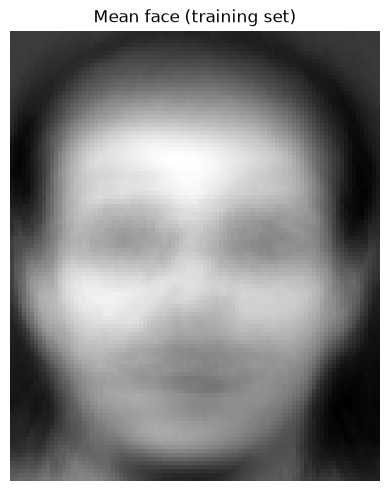

In [5]:
# Mean-center using training data only.
mean_face = X_train_raw.mean(axis=0)
X_train_centered = X_train_raw - mean_face
X_test_centered = X_test_raw - mean_face

plt.figure(figsize=(4, 5))
plt.imshow(mean_face.reshape(images.shape[1:]), cmap="gray")
plt.title("Mean face (training set)")
plt.axis("off")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "mean_face.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
# Method 1: dual covariance eigendecomposition using NumPy.
# Eigenvectors of Xc @ Xc.T map to eigenfaces in pixel space.
start = time.perf_counter()
gram = X_train_centered @ X_train_centered.T
eigvals_cov, eigvecs_sample = np.linalg.eigh(gram)
order_cov = np.argsort(eigvals_cov)[::-1]
eigvals_cov = np.maximum(eigvals_cov[order_cov], 0.0)
eigvecs_sample = eigvecs_sample[:, order_cov]

positive = eigvals_cov > 1e-10
eigvals_cov = eigvals_cov[positive]
eigvecs_sample = eigvecs_sample[:, positive]

eigenfaces_cov = (X_train_centered.T @ eigvecs_sample) / np.sqrt(eigvals_cov)[None, :]
# Normalize columns against small numerical errors.
eigenfaces_cov /= np.maximum(np.linalg.norm(eigenfaces_cov, axis=0), 1e-15)
covariance_seconds = time.perf_counter() - start

variance_cov = eigvals_cov / eigvals_cov.sum()
cumulative_cov = np.cumsum(variance_cov)
k90_cov = int(np.searchsorted(cumulative_cov, 0.90) + 1)
print(f"Dual-covariance eigendecomposition time: {covariance_seconds:.3f} s")
print("Eigenface matrix:", eigenfaces_cov.shape)
print(f"Components needed for ≥90% variance: {k90_cov}")
print(f"Cumulative variance at {k90_cov} components: {cumulative_cov[k90_cov-1]:.4f}")

Dual-covariance eigendecomposition time: 0.630 s
Eigenface matrix: (10304, 279)
Components needed for ≥90% variance: 89
Cumulative variance at 89 components: 0.9005


In [7]:
# Method : singular value decomposition (SVD).
start = time.perf_counter()
U_svd, singular_values, Vt_svd = np.linalg.svd(
    X_train_centered, full_matrices=False
)
svd_seconds = time.perf_counter() - start

eigenfaces_svd = Vt_svd.T
eigenvalues_svd = singular_values ** 2
variance_svd = eigenvalues_svd / eigenvalues_svd.sum()
cumulative_svd = np.cumsum(variance_svd)
k90_svd = int(np.searchsorted(cumulative_svd, 0.90) + 1)

print(f"SVD time: {svd_seconds:.3f} s")
print("SVD eigenface matrix:", eigenfaces_svd.shape)
print(f"Components needed for ≥90% variance: {k90_svd}")
print(f"Cumulative variance at {k90_svd} components: {cumulative_svd[k90_svd-1]:.4f}")

# Compare the two approaches by explained variance and leading-subspace similarity.
n_compare = min(20, eigenfaces_cov.shape[1], eigenfaces_svd.shape[1])
subspace_cosines = np.linalg.svd(
    eigenfaces_cov[:, :n_compare].T @ eigenfaces_svd[:, :n_compare],
    compute_uv=False
)
print("Mean cosine of principal angles for first", n_compare,
      "directions:", float(np.mean(np.clip(subspace_cosines, 0, 1))))
print("Note: small timing differences depend on hardware and BLAS implementation.")

SVD time: 1.214 s
SVD eigenface matrix: (10304, 280)
Components needed for ≥90% variance: 89
Cumulative variance at 89 components: 0.9005
Mean cosine of principal angles for first 20 directions: 0.9999999999999998
Note: small timing differences depend on hardware and BLAS implementation.


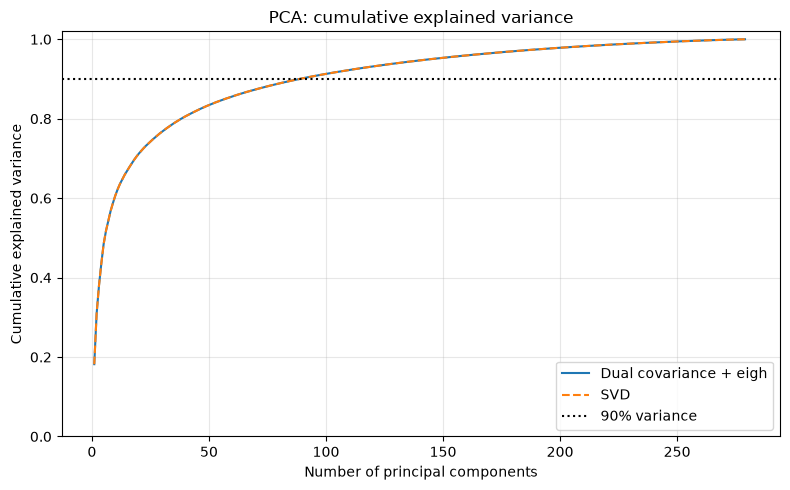

k for 90% variance (covariance): 89
k for 90% variance (SVD): 89


In [8]:
# Plot cumulative explained variance for both NumPy implementations.
plt.figure(figsize=(8, 5))
plt.plot(np.arange(1, len(cumulative_cov)+1), cumulative_cov, label="Dual covariance + eigh")
plt.plot(np.arange(1, len(cumulative_svd)+1), cumulative_svd, "--", label="SVD")
plt.axhline(0.90, linestyle=":", color="black", label="90% variance")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA: cumulative explained variance")
plt.ylim(0, 1.02)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "explained_variance.png", dpi=150)
plt.show()

print("k for 90% variance (covariance):", k90_cov)
print("k for 90% variance (SVD):", k90_svd)

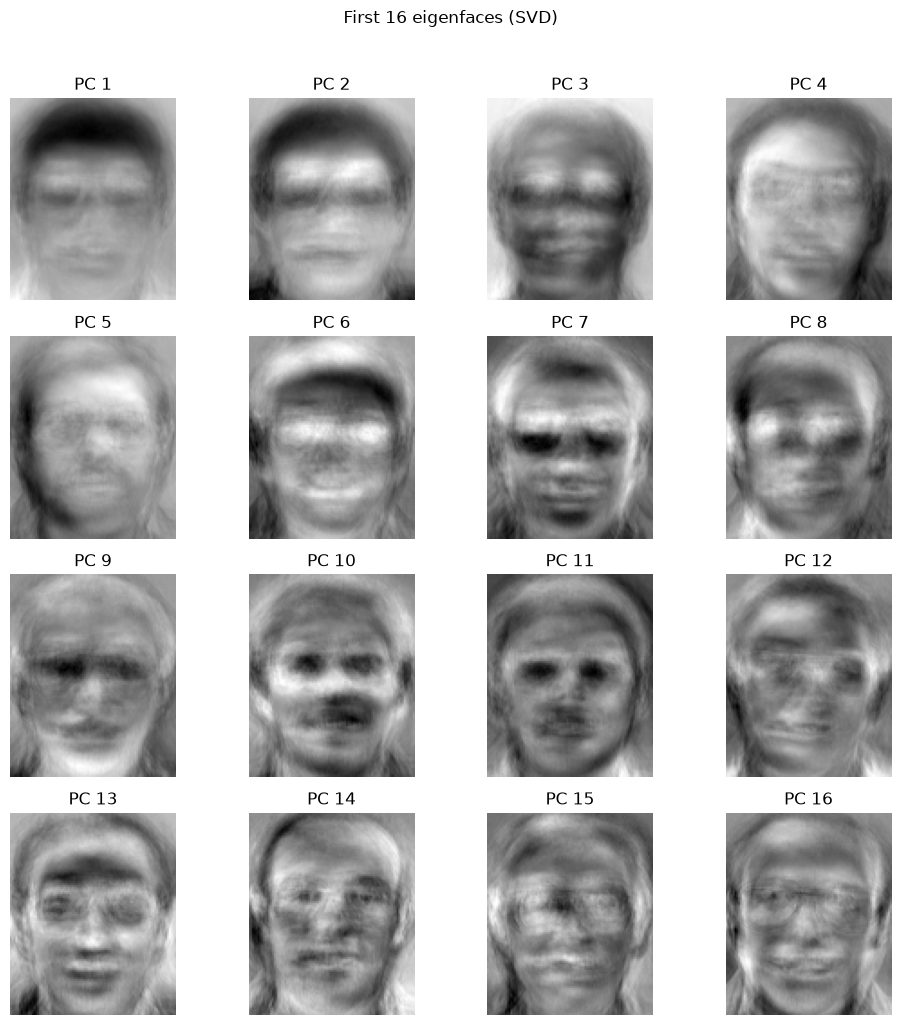

In [9]:
# Use SVD directions for the rest of the notebook.
# SVD is stable and its singular values directly provide variance proportions.
components = eigenfaces_svd
explained_variance_ratio = variance_svd
cumulative_variance = cumulative_svd
k90 = k90_svd

# Display the first 16 eigenfaces. Eigenfaces contain positive and negative
# deviations from the mean face, so a diverging-looking grayscale image is normal.
n_show = min(16, components.shape[1])
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for i, ax in enumerate(axes.flat):
    if i < n_show:
        eigenface = components[:, i].reshape(images.shape[1:])
        ax.imshow(eigenface, cmap="gray")
        ax.set_title(f"PC {i+1}")
    ax.axis("off")
fig.suptitle("First 16 eigenfaces (SVD)", y=1.02)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "eigenfaces.png", dpi=150, bbox_inches="tight")
plt.show()

### Project into PCA space and reconstruct faces



PCA training scores: (280, 89)
PCA testing scores: (120, 89)
Test reconstruction MAE: 13.492 intensity levels
Test reconstruction RMSE: 18.909 intensity levels


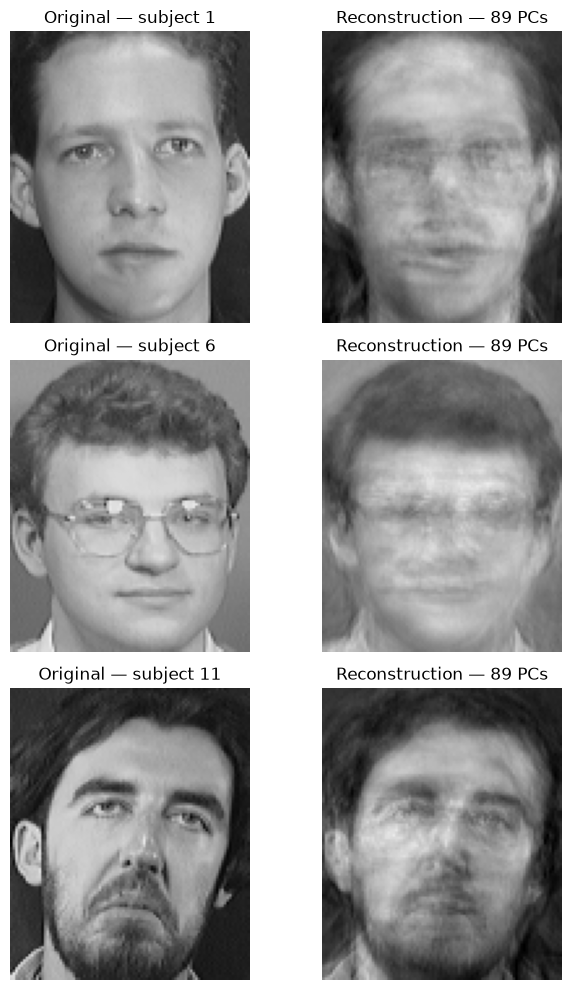

Original values per image: 10,304
Compressed coefficients per image: 89
Approximate per-image coefficient reduction: 99.14%
Shared PCA basis and mean face must also be stored once.


In [10]:
# Retain the smallest component count meeting 90% variance.
W90 = components[:, :k90]
Z_train_90 = X_train_centered @ W90
Z_test_90 = X_test_centered @ W90

X_test_reconstructed = Z_test_90 @ W90.T + mean_face
reconstruction_mae = np.mean(np.abs(X_test_raw - X_test_reconstructed))
reconstruction_rmse = np.sqrt(np.mean((X_test_raw - X_test_reconstructed) ** 2))
print("PCA training scores:", Z_train_90.shape)
print("PCA testing scores:", Z_test_90.shape)
print(f"Test reconstruction MAE: {reconstruction_mae:.3f} intensity levels")
print(f"Test reconstruction RMSE: {reconstruction_rmse:.3f} intensity levels")

# Show examples with the original and reconstruction side by side.
example_indices = [0, 15, 30]
fig, axes = plt.subplots(len(example_indices), 2, figsize=(7, 10))
for row, idx in enumerate(example_indices):
    axes[row, 0].imshow(X_test_raw[idx].reshape(images.shape[1:]), cmap="gray", vmin=0, vmax=255)
    axes[row, 0].set_title(f"Original — subject {y_test[idx]}")
    axes[row, 1].imshow(
        np.clip(X_test_reconstructed[idx].reshape(images.shape[1:]), 0, 255),
        cmap="gray", vmin=0, vmax=255
    )
    axes[row, 1].set_title(f"Reconstruction — {k90} PCs")
    for ax in axes[row]:
        ax.axis("off")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "reconstruction_examples.png", dpi=150, bbox_inches="tight")
plt.show()

# Save reconstruction images for inspection.
for idx in example_indices:
    recon = np.clip(X_test_reconstructed[idx].reshape(images.shape[1:]), 0, 255).astype(np.uint8)
    Image.fromarray(recon).save(RECON_DIR / f"test_subject_{y_test[idx]}_reconstruction.png")

original_values = X_train_raw.shape[1]
compressed_values_per_image = k90 + k90 + X_train_raw.shape[1]  # scores + shared basis + mean
# Per-image comparison excludes the shared basis and mean, which are stored once.
print(f"Original values per image: {original_values:,}")
print(f"Compressed coefficients per image: {k90:,}")
print(f"Approximate per-image coefficient reduction: {100*(1-k90/original_values):.2f}%")
print("Shared PCA basis and mean face must also be stored once.")

## Part C — Recognition in PCA space

For each test face, find the training image with the smallest Euclidean distance in PCA space. The predicted identity is the label of that nearest training image. As a baseline, repeat nearest-neighbor matching using raw pixel values.

**Interpretation note:** this is closed-set identification: each test subject has training examples in the gallery. Accuracy is the proportion of test images whose predicted subject matches the true subject.

In [11]:
def nearest_neighbor_predict(X_gallery, y_gallery, X_query):
    """Return nearest-gallery labels, indices, and nearest Euclidean distances."""
    # Squared Euclidean distances using ||a-b||² = ||a||² + ||b||² - 2a·b.
    gallery_norms = np.sum(X_gallery ** 2, axis=1)[None, :]
    query_norms = np.sum(X_query ** 2, axis=1)[:, None]
    distances_sq = query_norms + gallery_norms - 2 * (X_query @ X_gallery.T)
    distances_sq = np.maximum(distances_sq, 0.0)
    nearest_indices = np.argmin(distances_sq, axis=1)
    nearest_distances = np.sqrt(distances_sq[np.arange(len(X_query)), nearest_indices])
    return y_gallery[nearest_indices], nearest_indices, nearest_distances

# PCA-space matching with k90 components.
pred_pca, nearest_pca_idx, nearest_pca_dist = nearest_neighbor_predict(
    Z_train_90, y_train, Z_test_90
)
pca_accuracy = np.mean(pred_pca == y_test)

# Raw-pixel matching uses centered raw pixels for a fairer distance scale.
pred_raw, nearest_raw_idx, nearest_raw_dist = nearest_neighbor_predict(
    X_train_centered, y_train, X_test_centered
)
raw_accuracy = np.mean(pred_raw == y_test)

print(f"PCA-space nearest-neighbor accuracy ({k90} PCs): {pca_accuracy:.4f}")
print(f"Raw-pixel nearest-neighbor accuracy: {raw_accuracy:.4f}")

PCA-space nearest-neighbor accuracy (89 PCs): 0.9667
Raw-pixel nearest-neighbor accuracy: 0.9500


Correct matches: 116 / 120
Incorrect matches: 4 / 120


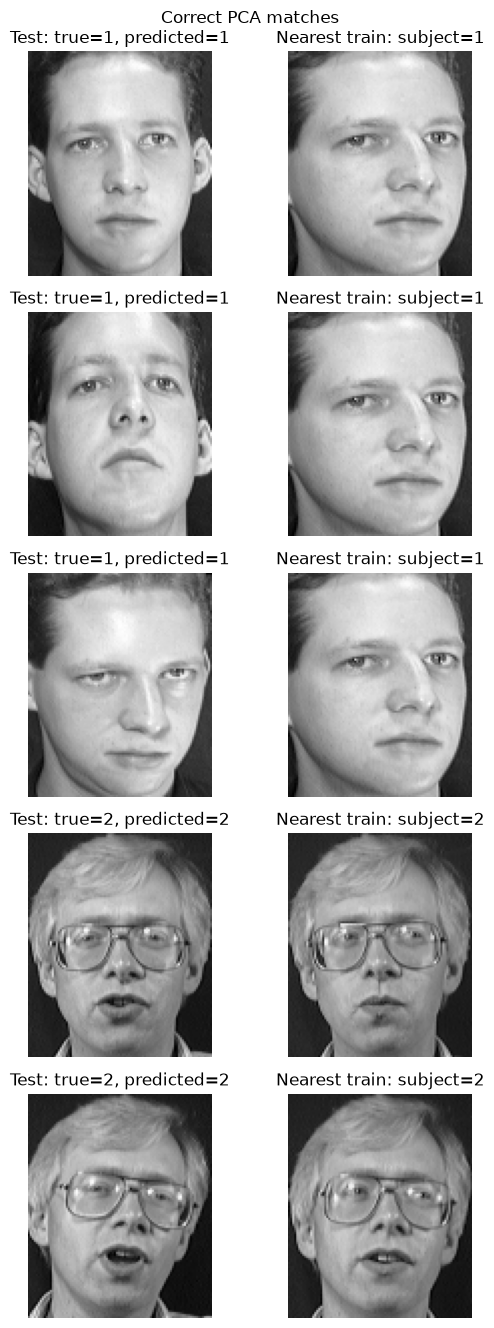

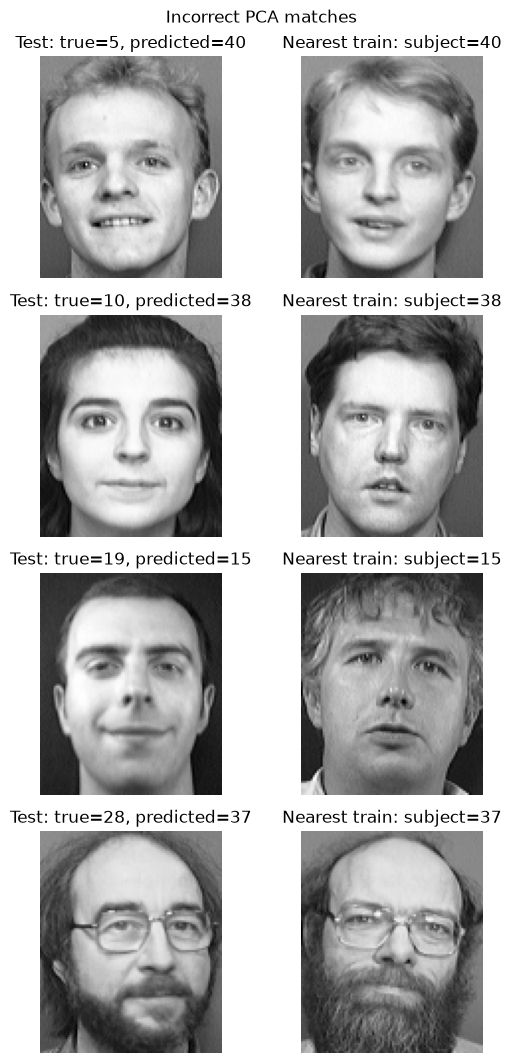

In [12]:
# Inspect a few correct and incorrect PCA-space matches.
correct_indices = np.where(pred_pca == y_test)[0]
incorrect_indices = np.where(pred_pca != y_test)[0]
print(f"Correct matches: {len(correct_indices)} / {len(y_test)}")
print(f"Incorrect matches: {len(incorrect_indices)} / {len(y_test)}")

def show_matches(test_indices, title, max_items=5):
    selected = test_indices[:max_items]
    if len(selected) == 0:
        print("No examples to display for:", title)
        return
    fig, axes = plt.subplots(len(selected), 2, figsize=(6, 2.7 * len(selected)))
    if len(selected) == 1:
        axes = np.array([axes])
    for row, test_idx in enumerate(selected):
        train_idx = nearest_pca_idx[test_idx]
        axes[row, 0].imshow(X_test_raw[test_idx].reshape(images.shape[1:]), cmap="gray")
        axes[row, 0].set_title(f"Test: true={y_test[test_idx]}, predicted={pred_pca[test_idx]}")
        axes[row, 1].imshow(X_train_raw[train_idx].reshape(images.shape[1:]), cmap="gray")
        axes[row, 1].set_title(f"Nearest train: subject={y_train[train_idx]}")
        for ax in axes[row]:
            ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    safe_title = title.lower().replace(" ", "_")
    plt.savefig(FIGURE_DIR / f"{safe_title}.png", dpi=150, bbox_inches="tight")
    plt.show()

show_matches(correct_indices, "Correct PCA matches")
show_matches(incorrect_indices, "Incorrect PCA matches")

## Part D — Traditional machine-learning classifiers

We train **K-Nearest Neighbors** and **Logistic Regression** using PCA scores. The PCA transform is still the NumPy implementation above; only the classifiers use scikit-learn. We test several retained component counts and report accuracy, precision, recall, and F1 score. The test set is not used to fit the PCA basis or classifiers.

In [13]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def metric_row(name, y_true, y_pred, components_used=None, setting=""):
    return {
        "Model": name,
        "Components": components_used,
        "Setting": setting,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }


component_candidates = sorted(set([min(20, components.shape[1]), min(40, components.shape[1]), k90]))
component_candidates = [k for k in component_candidates if k >= 1]
results = []

for k in component_candidates:
    W = components[:, :k]
    Ztr = X_train_centered @ W
    Zte = X_test_centered @ W

    knn = KNeighborsClassifier(n_neighbors=1, metric="euclidean")
    knn.fit(Ztr, y_train)
    pred_knn = knn.predict(Zte)
    results.append(metric_row("KNN", y_test, pred_knn, k, "n_neighbors=1"))

    logreg = LogisticRegression(max_iter=3000, random_state=SEED)
    logreg.fit(Ztr, y_train)
    pred_logreg = logreg.predict(Zte)
    results.append(metric_row("Logistic Regression", y_test, pred_logreg, k, "max_iter=3000"))

results.append(metric_row("Nearest neighbor (PCA)", y_test, pred_pca, k90, "Euclidean"))
results.append(metric_row("Nearest neighbor (raw pixels)", y_test, pred_raw, None, "Euclidean"))


import pandas as pd
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(["Accuracy", "F1_macro"], ascending=False).reset_index(drop=True)
display(results_df.round(4))
results_df.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)

,Model,Components,Setting,Accuracy,Precision_macro,Recall_macro,F1_macro
0,Logistic Regression,40.0,max_iter=3000,0.9667,0.9750,0.9667,0.9657
1,KNN,89.0,n_neighbors=1,0.9667,0.9750,0.9667,0.9657
2,Nearest neighbor (PCA),89.0,Euclidean,0.9667,0.9750,0.9667,0.9657
3,KNN,20.0,n_neighbors=1,0.9583,0.9712,0.9583,0.9580
4,KNN,40.0,n_neighbors=1,0.9583,0.9712,0.9583,0.9580
5,Nearest neighbor (raw pixels),NaN,Euclidean,0.9500,0.9583,0.9500,0.9490
6,Logistic Regression,20.0,max_iter=3000,0.9417,0.9567,0.9417,0.9386
7,Logistic Regression,89.0,max_iter=3000,0.9250,0.9442,0.9250,0.9215


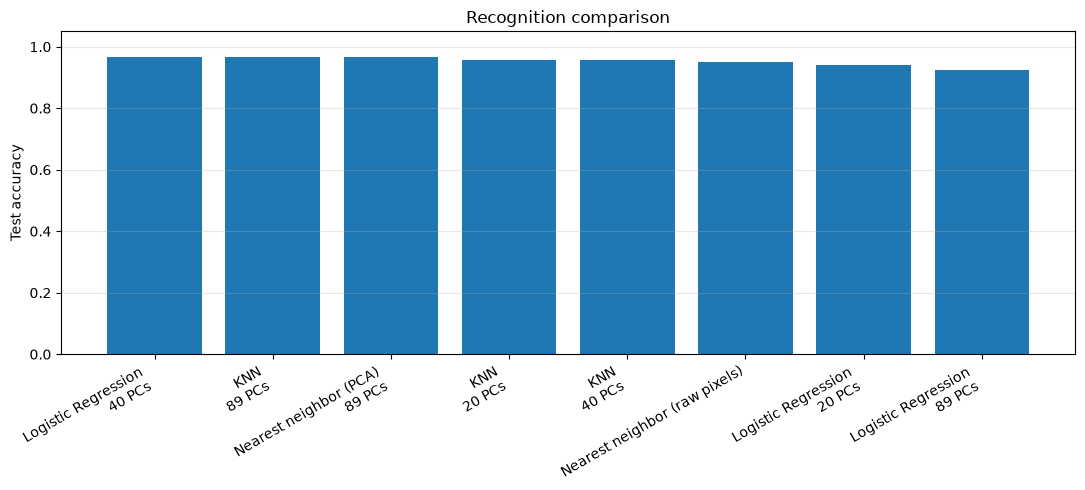

In [14]:
# Plot accuracy by method / component count.
plot_df = results_df.copy()
plot_df["Label"] = plot_df.apply(
    lambda row: f"{row['Model']}\n{int(row['Components'])} PCs"
    if pd.notna(row["Components"]) else row["Model"],
    axis=1
)
plt.figure(figsize=(11, 5))
plt.bar(plot_df["Label"], plot_df["Accuracy"])
plt.ylabel("Test accuracy")
plt.title("Recognition comparison")
plt.ylim(0, 1.05)
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "model_accuracy_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## Experiment: tune KNN settings

The assignment asks you to experiment with retained components and suitable model settings. The following loop evaluates a small set of K values on the same fixed test set. For a rigorous final model-selection estimate, use a validation split from the training data and keep the test set for the final report.

In [15]:
knn_tuning_rows = []
k_tune = k90
W = components[:, :k_tune]
Ztr = X_train_centered @ W
Zte = X_test_centered @ W

for n_neighbors in [1, 3, 5, 7]:
    model = KNeighborsClassifier(n_neighbors=n_neighbors, metric="euclidean", weights="uniform")
    model.fit(Ztr, y_train)
    pred = model.predict(Zte)
    knn_tuning_rows.append({
        "n_neighbors": n_neighbors,
        "components": k_tune,
        "accuracy": accuracy_score(y_test, pred),
        "macro_f1": f1_score(y_test, pred, average="macro", zero_division=0)
    })

knn_tuning_df = pd.DataFrame(knn_tuning_rows)
display(knn_tuning_df.round(4))
knn_tuning_df.to_csv(OUTPUT_DIR / "knn_tuning.csv", index=False)

,n_neighbors,components,accuracy,macro_f1
0,1,89,0.9667,0.9657
1,3,89,0.9167,0.9129
2,5,89,0.8917,0.8888
3,7,89,0.8500,0.8382


## Final summary and exported outputs



In [16]:
summary = {
    "dataset": "AT&T / ORL Database of Faces",
    "total_images": int(len(X)),
    "subjects": int(len(np.unique(labels))),
    "image_height": int(images.shape[1]),
    "image_width": int(images.shape[2]),
    "flattened_features": int(X.shape[1]),
    "train_images": int(len(X_train_raw)),
    "test_images": int(len(X_test_raw)),
    "covariance_components_for_90_percent": int(k90_cov),
    "svd_components_for_90_percent": int(k90_svd),
    "test_reconstruction_mae": float(reconstruction_mae),
    "test_reconstruction_rmse": float(reconstruction_rmse),
    "pca_nearest_neighbor_accuracy": float(pca_accuracy),
    "raw_pixel_nearest_neighbor_accuracy": float(raw_accuracy),
    "covariance_runtime_seconds": float(covariance_seconds),
    "svd_runtime_seconds": float(svd_seconds)
}
with open(OUTPUT_DIR / "summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))
print("\nFiles saved under:", OUTPUT_DIR.resolve())
print("Figures:", FIGURE_DIR.resolve())
print("Model comparison:", (OUTPUT_DIR / "model_comparison.csv").resolve())

{
  "dataset": "AT&T / ORL Database of Faces",
  "total_images": 400,
  "subjects": 40,
  "image_height": 112,
  "image_width": 92,
  "flattened_features": 10304,
  "train_images": 280,
  "test_images": 120,
  "covariance_components_for_90_percent": 89,
  "svd_components_for_90_percent": 89,
  "test_reconstruction_mae": 13.492492765972605,
  "test_reconstruction_rmse": 18.90904426293552,
  "pca_nearest_neighbor_accuracy": 0.9666666666666667,
  "raw_pixel_nearest_neighbor_accuracy": 0.95,
  "covariance_runtime_seconds": 0.629816500000743,
  "svd_runtime_seconds": 1.214274199999636
}

Files saved under: C:\Users\diash\OneDrive\Desktop\python\outputs
Figures: C:\Users\diash\OneDrive\Desktop\python\outputs\figures
Model comparison: C:\Users\diash\OneDrive\Desktop\python\outputs\model_comparison.csv


## Observations to write in your submission

Use the measured results from your own notebook run and explain:

1. **Representation:** each 112 × 92 image becomes a 10,304-feature vector; the dataset has 400 images from 40 subjects.
2. **PCA implementations:** covariance/eigendecomposition and SVD should produce closely matching explained-variance curves, aside from floating-point differences. Their execution times can differ by machine.
3. **Dimensionality reduction:** report the number of components needed to preserve at least 90% variance and the corresponding reduction from 10,304 pixel values to that many coefficients per image.
4. **Reconstruction:** describe the visible differences between original and reconstructed faces and quote the measured MAE/RMSE.
5. **Recognition:** compare PCA-space nearest-neighbor accuracy against raw-pixel matching; show examples of correct and incorrect matches.
6. **Classifiers:** compare KNN and Logistic Regression against similarity-based matching. Discuss how accuracy changes with the number of components and KNN's neighbor count.
